This is a tutorial of introduction, first we use Qiskit to make a simulation, and later we will explain how to use the [IBM Quantum Platform](https://www.ibm.com/quantum/qiskit). After 2025 July 1 we will update this notes.

Resources:
1. The composer: [IBM Q Experience Composer](https://quantumexperience.ng.bluemix.net/qx/editor)
2. The python package: [Qiskit](https://qiskit.org)
3. Basic architecture of quantum gates: [IBM Q tutorial of basic gates](https://web.archive.org/web/20190715080739/https://quantumexperience.ng.bluemix.net/proxy/tutorial/full-user-guide/004-Quantum_Algorithms/061-Basic_Circuit_Identities_and_Larger_Circuits.html)
4. The Qiskit tutorial: [Qiskit tutorial](https://nbviewer.jupyter.org/github/Qiskit/qiskit-tutorial/blob/master/qiskit/basics/getting_started_with_qiskit_terra.ipynb)
5. Trouble shooting for Qiskit: [Qiskit Document](https://qiskit.org/documentation/install.html)


<br>
<br>
<br>
<font size='6' style="color:#00A6D6">  <b>1. Preparation</b></font>

In this section, I will demonstrate how to install the python package, qiskit


<br>
<br>
<font size='5' style="color:#4CAF50">  <b>1.1 Installation of Qiskit</b></font>

There is an instruction on their website: [Qiskit](https://qiskit.org). It requires Python version >= 3.5, and "**pip install qiskit**" for most linux/unix users. 

For windows user, I recommand [Anaconda](https://www.anaconda.com) to manage python versions and packages. Once installed, you can open "Anaconda Prompt" to launch a terminal-like window to install qiskit.



<br>
<br>
<br>
<font size='6' style="color:#00A6D6">  <b>2. Working with Qiskit</b></font>

You may noticed from the account information page, that using qiskit can access to 16-qubit quantum chips and also to simulate and visualize your circuit. Their website has a straight-forware [Qiskit tutorial](https://quantum.cloud.ibm.com/docs/en/guides/hello-world). From the Qiskit program, we don't need to take care of the connection problem (for now). The connection of tquantum hardware varies and it will be taken care of by the qiskit.

<br>
<br>
<font size='5' style="color:#4CAF50">  <b>2.1 Examples of Quantum Algorithms</b></font>

### 2.1.1 Quantum half-adder
The quantum half-adder is a working algorithm and fun to start. The circuit is

In [13]:
from IPython.display import Image

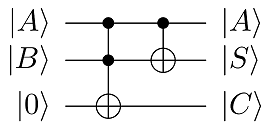

In [14]:

Image('quantum_half_adder.png')

### 2.1.2 Grover's search algorithm
The Grover's search algorithm is difficult to build on the web interface. The circuit is then:

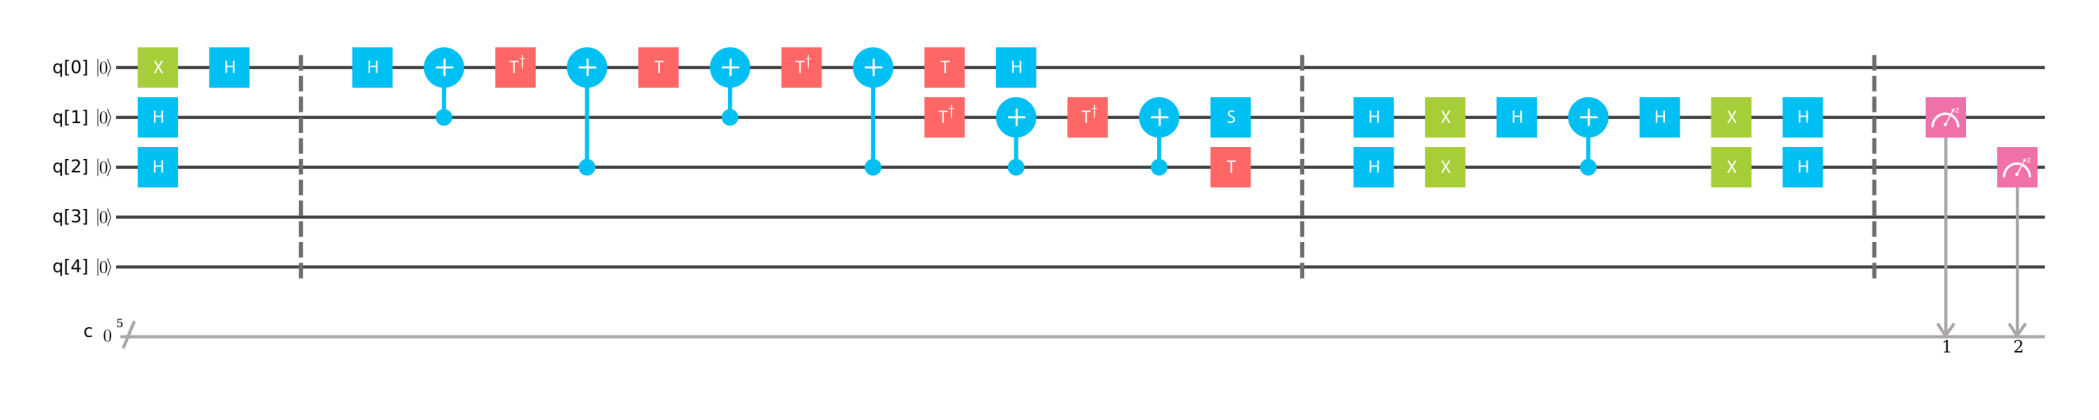

In [15]:
Image('grover_circuit.png')

Remember, the second subroutine is the oracle, which is a Toffoli gate to search number 3.

<br>
<br>
<font size='5' style="color:#4CAF50">  <b>3 Programming</b></font>

From the tutorial, it is straight forward to build a fundation to simulate/execute a quantum circuit. We can later substitute the core algorithm part for further implementations.

In [ ]:
##In case you do not have the libraries, and you are running this notebook, you need to remove the "#" from the lines below:
#!pip install qiskit
#!pip install qiskit-aer
#!pip install pylatexenc

In [16]:
"""
Quantum circuit for quantum half-adder / Grover's algorithm
Updated to be compatible with Qiskit 1.x (2025-06-26)
"""
import math
import matplotlib.pyplot as plt
import matplotlib
matplotlib.use('TkAgg') 
import numpy as np
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit.visualization import plot_histogram


In [17]:
# Parameters
num_qubit = 5
qr = QuantumRegister(num_qubit, 'qr') # Create a quantum register called "qr" with " num_qubit" qubits
cr = ClassicalRegister(num_qubit, 'c') # Create a Quantum Circuit
qc = QuantumCircuit(qr, cr) # Create a Quantum Circuit called "qc". involving the Quantum Register "qr"

# Quantum half-adder
##### Initial state
qc.x(qr[0]) # qr[0] represent the first input bit set to 1
qc.x(qr[1]) # same as qr[0], after the quantum algorithm, it is then the sum
# qr[2] is the carry bit.

##### Start of the quantum circuit #####
qc.ccx(qr[0], qr[1], qr[2])
qc.cx(qr[0], qr[1])


In [18]:
# Grover's search 

##### Initial state
qc.x(qr[0])
qc.h(qr[0])
qc.h(qr[1])  # qr[1] and qr[2] are the output
qc.h(qr[2])

## Grover's operator
### The Oracle to find 3 in {0:3}
qc.ccx(qr[1], qr[2], qr[0])

### Flip
qc.h(qr[1])
qc.h(qr[2])

qc.x(qr[1])
qc.x(qr[2])

qc.h(qr[1])
qc.cx(qr[2], qr[1])
qc.h(qr[1])

qc.x(qr[1])
qc.x(qr[2])

qc.h(qr[1])
qc.h(qr[2])

qc.h(qr[0])
qc.x(qr[0])
### END of quantum algorithm




In [19]:


qc.barrier() 
qc.measure(qr, cr) # map the quantum measurement to the classical bits

# Simulation
simulator = AerSimulator()
compiled = transpile(qc, simulator)
job = simulator.run(compiled, shots=8000)
result = job.result()  # Grab the results from the job.
counts = result.get_counts()
print("Simulation result:", counts)

plot_histogram(counts).show() #perhaps you need to run this twice to see the histogram
#plt.savefig("histogram.png")


Simulation result: {'00111': 2007, '00011': 1989, '00001': 2033, '00101': 1971}


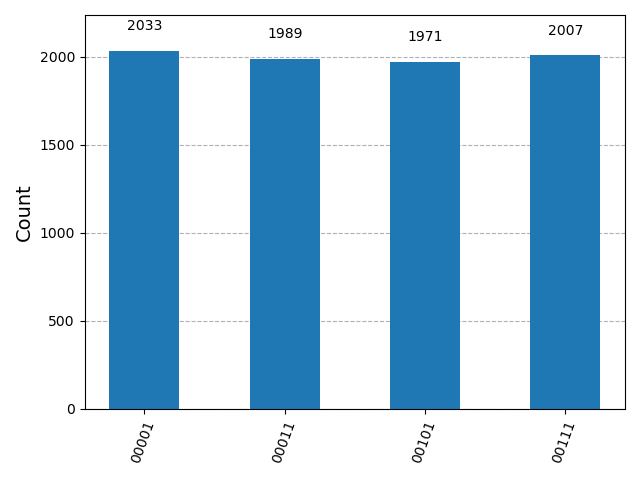

In [21]:
#in my run I got

Image('sample.png')

In [20]:

# Circuit visualization
fig = qc.draw('mpl')
fig.show()

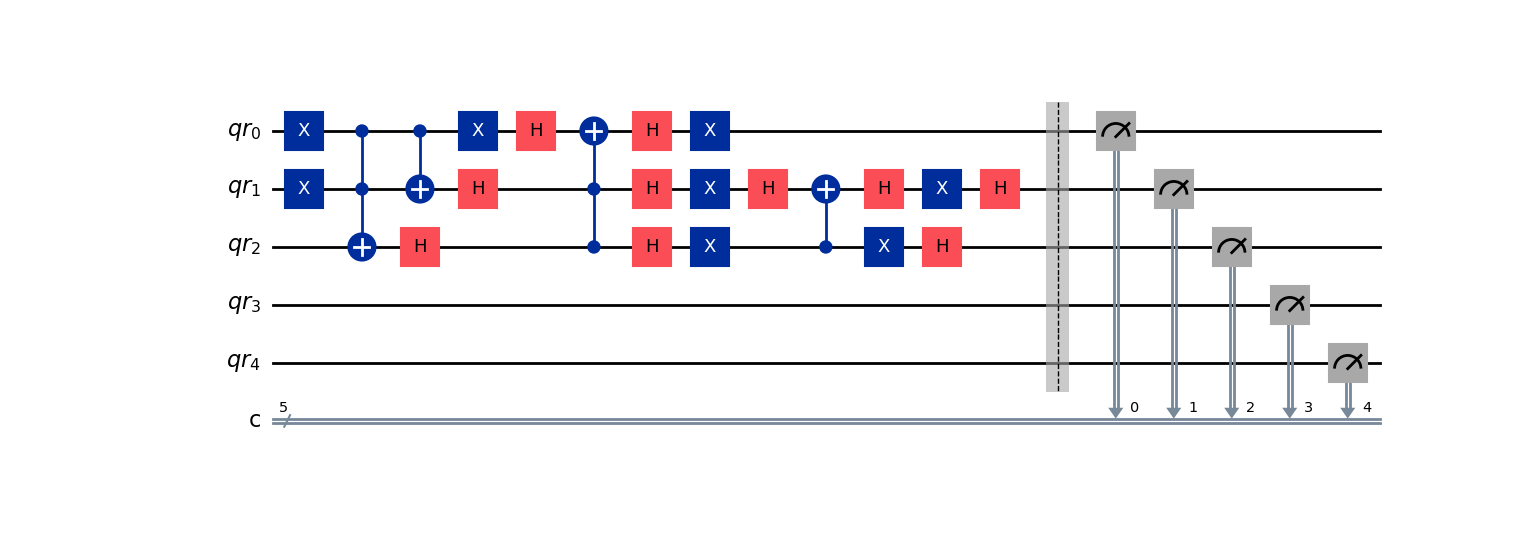

In [23]:
#in my run i got

Image('sample2.png')

> Try to play with the circuit to realise 0+1 and search number 2 in the database {0:3}

> Does the naming of the qubits effect the implementation results? How different are the result using qiskit and using web interface?

> Optimizing the circuit? For example, HXH=Z, which means we can reduce the number of quantum gates. 

<br>
<br>
<br>
<font size='6' style="color:#00A6D6">  <b>4. Open Questions</b></font>

Up to now, the IBM Q team is continuing developing this package to tackle more complex problems. However, with only the basic  of qiskit, we are able to design, to simulate and to implement quantum algorithms. The poor performace of the implementation of quantum algorithm still needs deep understandings of errors and optimizations of circuits.

